# Firmas nivel 2: orden, geometría y aliasing
## Resumen
En simulación el nivel 2 separa orientación sin ruido; endpoints y momentos no distinguen pares reversos. Con ruido alto falla. Auditoría S2 de un componente del programa 13, sin evidencia operativa.
## Contexto y métodos
Trayectorias poligonales finitas en $\mathbb R^d$.
$S_1=\sum_i\Delta x_i$, $S_2=\sum_{i<j}\Delta x_i\otimes\Delta x_j+\frac12\sum_i\Delta x_i\otimes\Delta x_i$.
Composición de Chen: $(a,b)*(c,d)=(a+c,b+d+a\otimes c)$. Al añadir segmento $v$ se multiplica por $(v,v\otimes v/2)$.
Área: $A=(S_2^{12}-S_2^{21})/2$, oráculo independiente shoelace cerrando por cuerda.
### Supuestos
Etiqueta sintética de orientación latente antes del ruido. Los pares reversos tienen los mismos puntos y resúmenes marginales: cualquier clasificador determinista sobre dichos resúmenes predice igual para ambos, por lo que acierta exactamente uno. No se afirma reconstrucción ni innovación algorítmica mundial.
## Datos
Semilla 422; 100 pares por nivel de ruido. Los miembros del par no son independientes.

In [1]:
import json, csv
from pathlib import Path
from IPython.display import display, Image
results=Path('results')
config=json.loads(Path('config.json').read_text())
config

Out[0]: 
{'seed': 422,
 'n_points': [8, 16, 32, 64, 128, 256],
 'replicates': 100,
 'noise_sd': [0, 0.05, 0.25, 1.0],
 'area_tolerance': 1e-10,
 'orientation_accuracy_threshold': 0.95}


## Resultados
Los CSV preservan réplicas y medidas. Shoelace es más específico y eficiente para área planar: no se pretende superarlo.

In [2]:
summary=json.loads((results/'summary.json').read_text())
summary

Out[0]: 
{'seed': 422,
 'samples': 800,
 'accuracy_by_noise': {'0': 1.0, '0.05': 1.0, '0.25': 1.0, '1.0': 0.7},
 'endpoint_accuracy': 0.5,
 'moments_accuracy': 0.5,
 'max_oracle_error': 1.0658141036401503e-14,
 'convergence_order': 1.999869639150011,
 'aliasing_dense_area': 6.280662313909504,
 'aliasing_four_segment_area': 0.0,
 'python': '3.12.14',
 'numpy': '2.3.5',
 'hardware': 'x86_64',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39'}


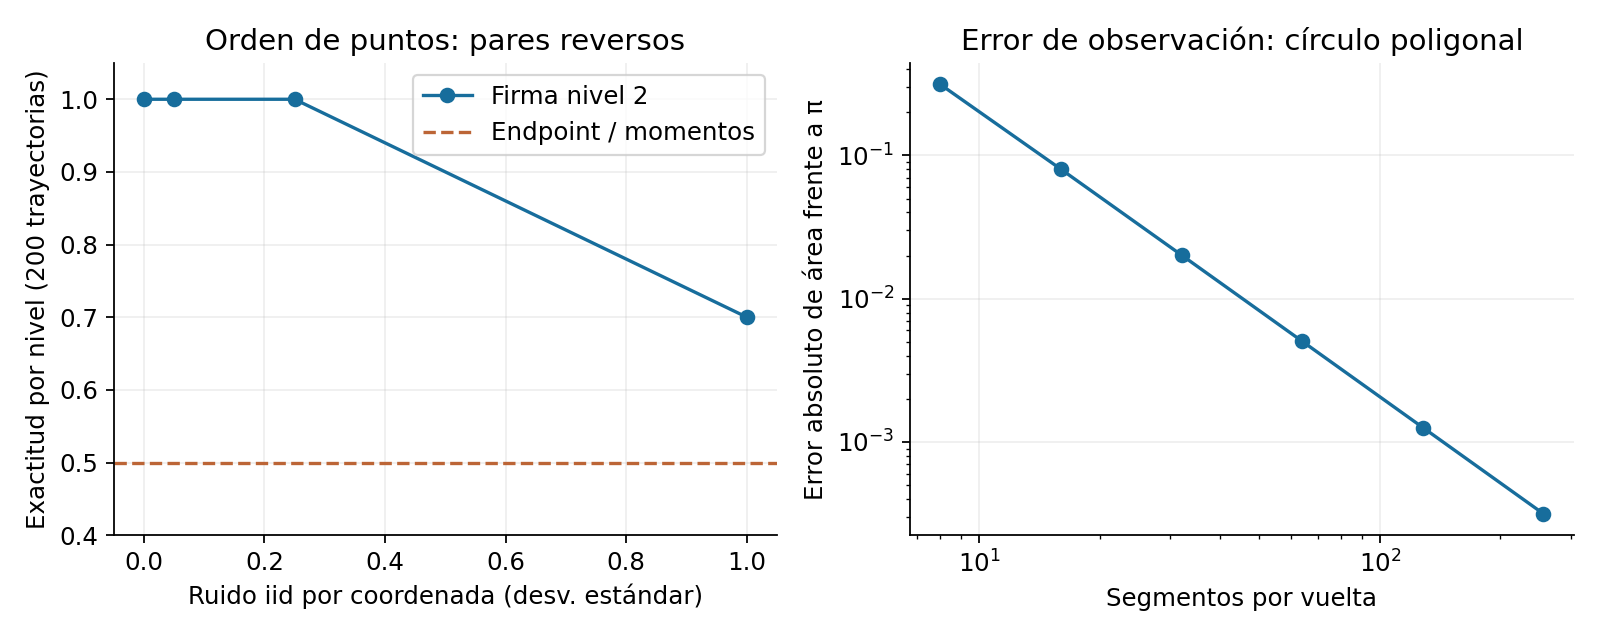

In [3]:
display(Image(filename=str(results/'audit.png')))

### Convergencia y recursos
El error frente a π es geométrico por observación poligonal. No es error de discretización de la recurrencia. La API conserva entrada batch; el estado recurrente requiere O(d²).

In [4]:
list(csv.DictReader((results/'convergence.csv').open()))

Out[0]: 
[{'segments': '8',
  'area': '2.8284271247461903',
  'polygon_exact': '2.82842712474619',
  'error_to_pi': '0.3131655288436028',
  'oracle_error': '4.440892098500626e-16'},
 {'segments': '16',
  'area': '3.0614674589207183',
  'polygon_exact': '3.0614674589207183',
  'error_to_pi': '0.08012519466907486',
  'oracle_error': '0.0'},
 {'segments': '32',
  'area': '3.121445152258052',
  'polygon_exact': '3.121445152258052',
  'error_to_pi': '0.020147501331741147',
  'oracle_error': '0.0'},
 {'segments': '64',
  'area': '3.136548490545939',
  'polygon_exact': '3.1365484905459393',
  'error_to_pi': '0.005044163043854244',
  'oracle_error': '4.440892098500626e-16'},
 {'segments': '128',
  'area': '3.140331156954752',
  'polygon_exact': '3.140331156954753',
  'error_to_pi': '0.0012614966350410484',
  'oracle_error': '8.881784197001252e-16'},
 {'segments': '256',
  'area': '3.141277250932771',
  'polygon_exact': '3.141277250932773',
  'error_to_pi': '0.00031540265702201253',
  'oracle_e

In [5]:
list(csv.DictReader((results/'scalability.csv').open()))

Out[0]: 
[{'segments': '64',
  'method': 'signature2',
  'seconds_median': '0.0010436929999286804',
  'peak_bytes': '2336'},
 {'segments': '64',
  'method': 'shoelace',
  'seconds_median': '0.00010037999982159818',
  'peak_bytes': '9304'},
 {'segments': '256',
  'method': 'signature2',
  'seconds_median': '0.003816696000058073',
  'peak_bytes': '2304'},
 {'segments': '256',
  'method': 'shoelace',
  'seconds_median': '0.0001032949999171251',
  'peak_bytes': '13912'},
 {'segments': '1024',
  'method': 'signature2',
  'seconds_median': '0.01581914999997025',
  'peak_bytes': '2972'},
 {'segments': '1024',
  'method': 'shoelace',
  'seconds_median': '0.00011765599992941134',
  'peak_bytes': '32376'},
 {'segments': '4096',
  'method': 'signature2',
  'seconds_median': '0.07039653400011048',
  'peak_bytes': '9116'},
 {'segments': '4096',
  'method': 'shoelace',
  'seconds_median': '0.00014316400006464391',
  'peak_bytes': '106104'}]


## Comprobaciones
Tests de Chen, shuffle, traslación, reversión, entradas inválidas y degeneración. Dos vueltas vistas con cuatro segmentos pierden el área: la exactitud numérica no corrige aliasing.

In [6]:
from src.signatures import signature, circle, signed_area
import numpy as np
a,b=signature(np.array([[0.,0.],[1.,2.],[0.,0.]]))
assert np.allclose(b,0)
assert summary['max_oracle_error'] < config['area_tolerance']
assert summary['accuracy_by_noise']['0'] >= config['orientation_accuracy_threshold']
print('Tree-like:', b.tolist())
print('Área densa:', signed_area(circle(256,turns=2)))
print('Área submuestreada:', signed_area(circle(4,turns=2)))

Tree-like: [[0.0, 0.0], [0.0, 0.0]]
Área densa: 6.280662313909504
Área submuestreada: 0.0


## Conclusiones
El nivel 2 añade orden frente a endpoints y momentos; no identifica caminos arbitrarios. Con ruido 1.0, 70% de exactitud refuta robustez universal. Falta validación externa. Bibliografía y verificación en referencias.bib y fuentes.md.